# Lab: Comparing Distributions Across Groups

Choose a new documented dataset with **at least one categorical feature and three quantitative features**. Develop and answer **three distinct research questions**, each comparing the distribution of a different quantitative feature across categorical groups. Use the six-step reproducible analysis workflow for each question, as in the Billboard lecture.

Your dataset must not have been used in any class demonstration or lab, including your own earlier lab submissions.


## Learning goals

- Select and document a new dataset suitable for comparing distributions.
- Distinguish meaningful quantitative measurements from identifiers and category codes.
- Develop three questions and record predictions before analyzing their results.
- Compare group sizes, center, spread, shape, overlap, and unusual observations.
- Check calculations against original records and write supported conclusions and limitations.


## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context? Do original records support the calculation and interpretation?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete all six steps separately for each question. Inspect the dataset once, then explain the observations, features, and preparation relevant to each investigation. Use separate code cells for individual operations and add cells as needed.


## Using AI tools responsibly

You may use AI for questions, debugging, or feedback. You remain responsible for understanding the code, reading the actual source documentation, and checking claims against your output. Disclose AI use and describe a suggestion you checked in the final reflection.


## Find and document a new dataset

Choose a manageable CSV from a documented source, such as a government open-data portal, a research repository, or Kaggle. It must have:

- A named publisher or creator and a data dictionary or equivalent feature documentation.
- At least one meaningful categorical feature with two or more groups containing multiple observations.
- At least three distinct quantitative measurements with documented meanings and units. Numeric IDs, category codes, and alternate-unit copies of the same measurement do not count as three quantitative features.
- Enough usable observations in each comparison group to examine distributions. There is no universal minimum group size for this descriptive exercise; justify exclusions and acknowledge sparse groups.
- A topic and dataset that have not already been used in class or any lab. A different filename, subset, or download of a previously used dataset does not make it new.

Review the course notebooks and your previous submissions. Examples already used include Billboard number-one songs, Titanic passengers, Pokémon, and penguins; this is not an exhaustive list.

Save the CSV in this notebook's `data` folder, use a relative path, and preserve the original records. Use a descriptive DataFrame name ending in `_df`. Your categorical feature can be reused across questions, or you may choose different categorical features for different questions.


**What are the dataset title, publisher or creator, direct source URL, data dictionary URL or location, and access date?**

Your answer: Dataset Title - Automobile 
Creator - Jeffrey Schlimmer
Source Url - https://archive.ics.uci.edu/dataset/10/automobile
data dictionary URL - https://archive.ics.uci.edu/dataset/10/automobile (Variables and Additional Variable Information sections)
Access Data - November 8, 2026



**Describe the dataset: what does one row represent, what time period and population or location does it cover, and how were observations collected? State when something is undocumented.**

Your answer: The dataset has information on 205 cars from 1985 Wards automobile. Each row shows a different car with information that includes make, fuel type, horsepower, price, and gas mileage. The data also includes insurance risk and loss information. The process used to collect the data is not fully explained.


**How did you confirm this dataset has not been used in class or any earlier lab, including your own submissions?**

Your answer: I checked the dataset from our class and I havent choosen to use this dataset previously.   

## Load and inspect the data

Use separate cells to import the libraries, load the CSV, and inspect its structure. Identify special missing codes from the dictionary; distinguish them from valid zeros.


In [4]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



In [6]:

columns = [
    "symboling", "normalized-losses", "make",
    "fuel-type", "aspiration", "num-of-doors",
    "body-style", "drive-wheels", "engine-location",
    "wheel-base", "length", "width", "height",
    "curb-weight", "engine-type", "num-of-cylinders",
    "engine-size", "fuel-system", "bore", "stroke",
    "compression-ratio", "horsepower", "peak-rpm",
    "city-mpg", "highway-mpg", "price"
]

automobile_df = pd.read_csv(
    "data/imports-85.data",
    names=columns,
    na_values="?"
)



In [7]:

automobile_df.head()



,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0


In [8]:

automobile_df.tail()



,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
200,-1,95.0,volvo,gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114.0,5400.0,23,28,16845.0
201,-1,95.0,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160.0,5300.0,19,25,19045.0
202,-1,95.0,volvo,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134.0,5500.0,18,23,21485.0
203,-1,95.0,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.40,23.0,106.0,4800.0,26,27,22470.0
204,-1,95.0,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114.0,5400.0,19,25,22625.0


In [9]:

automobile_df.shape



(205, 26)

In [10]:

automobile_df.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized-losses  164 non-null    float64
 2   make               205 non-null    object 
 3   fuel-type          205 non-null    object 
 4   aspiration         205 non-null    object 
 5   num-of-doors       203 non-null    object 
 6   body-style         205 non-null    object 
 7   drive-wheels       205 non-null    object 
 8   engine-location    205 non-null    object 
 9   wheel-base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb-weight        205 non-null    int64  
 14  engine-type        205 non-null    object 
 15  num-of-cylinders   205 non-null    object 
 16  engine-size        205 non


automobile_df.isna().sum()



### Document the features

Complete one row for **every feature**. Add rows as needed. For data type, use categorical or quantitative, and explicitly identify identifiers and temporal features where appropriate. Report the actual Pandas storage type separately.


| Feature | Meaning and units or category codes | Data type | Data storage type | Missing values |
| --- | --- | --- | --- | ---: |
| symboling | Insurance risk rating (-3 to 3) | Categorical (ordinal code) | int64 | 0 |
| normalized-losses | Normalized insurance losses | Quantitative | float64 | 41 |
| make | Car manufacturer | Categorical | object | 0 |
| fuel-type | Gas or diesel | Categorical | object | 0 |
| aspiration | Standard or turbo | Categorical | object | 0 |
| num-of-doors | Number of doors (two or four) | Categorical | object | 2 |
| body-style | Car body style | Categorical | object | 0 |
| drive-wheels | Front, rear, or four-wheel drive | Categorical | object | 0 |
| engine-location | Front or rear engine | Categorical | object | 0 |
| wheel-base | Distance between axles in inches | Quantitative | float64 | 0 |
| length | Vehicle length in inches | Quantitative | float64 | 0 |
| width | Vehicle width in inches | Quantitative | float64 | 0 |
| height | Vehicle height in inches | Quantitative | float64 | 0 |
| curb-weight | Vehicle weight in pounds | Quantitative | int64 | 0 |
| engine-type | Type of engine | Categorical | object | 0 |
| num-of-cylinders | Number of engine cylinders | Categorical | object | 0 |
| engine-size | Engine displacement in cubic inches | Quantitative | int64 | 0 |
| fuel-system | Type of fuel system | Categorical | object | 0 |
| bore | Engine cylinder bore in inches | Quantitative | float64 | 4 |
| stroke | Engine piston stroke in inches | Quantitative | float64 | 4 |
| compression-ratio | Engine compression ratio | Quantitative | float64 | 0 |
| horsepower | Engine horsepower (hp) | Quantitative | float64 | 2 |
| peak-rpm | Engine peak RPM | Quantitative | float64 | 2 |
| city-mpg | City fuel efficiency in MPG | Quantitative | int64 | 0 |
| highway-mpg | Highway fuel efficiency in MPG | Quantitative | int64 | 0 |
| price | Vehicle price in US dollars | Quantitative | float64 | 4 |

The dataset uses ? for missing values, so I changed them to NaN when loading the data into Pandas. I counted the missing values but haven't removed any records or replaced missing values with zero.


**Which categorical feature(s) and three quantitative features will you analyze? Why are they appropriate for distribution comparisons? Explain any missing codes or conversions.**

Your answer: I decided to use fuel type, drive wheels, and body style as my categorical features. The three quantitative features I chose are horsepower, price, and highway MPG. I chose these because I want to compare cars based on power, price, and gas mileage. The dataset uses ? for missing values which I changed to NaN when loading it into Pandas. I haven't removed any records or replaced missing values with zero.


## Plan three investigations

Write three specific questions. **Use a different quantitative feature for each question**, covering at least three in total. Each question must compare that feature's distribution across at least two categorical groups. You may reuse the same grouping feature. Changing only the plot type does not create a new question.

A useful question pattern is: “How does the distribution of [measurement and units] differ among [groups] in [documented population or period]?” Adapt it to your dataset's meaning. Similar distributions are a valid result; do not search for differences by repeatedly changing groups or discarding records.


## Investigation 1

### Step 1: Question


**What is research question 1? Name the quantitative feature, its units, and the categorical groups.**

Your answer: I want to see if gas cars have a different horse power than diesel cars. The quantitive feature is horsepower measured in hp and the categorical groups are gas and diesel. 


**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer: I think cars with gas will have more horsepower than diesel cars. I also think the gas cars will have more spread because there are different types of gas cars in the dataset. I think the horsepower values will overlap but gas cars will have more of higher numbers. 


### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer:I will use the automobile records that have a fuel type and horsepower value. The two groups will be gas and diesel and horsepower will be measured in hp. Each row represents one car. If a car is missing its horsepower value I won't include it in this comparison, but I will keep the original dataset unchanged.


In [12]:

horsepower_df = automobile_df[
    ["fuel-type", "horsepower"]
].dropna().copy()

horsepower_df.groupby("fuel-type")["horsepower"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)



,count,mean,median,std,min,max
fuel-type,,,,,,
diesel,20,84.450000,84.0,25.958418,52.0,123.0
gas,183,106.420765,97.0,40.402821,48.0,288.0


In [13]:

horsepower_df["fuel-type"].value_counts()



fuel-type
gas       183
diesel     20
Name: count, dtype: int64

### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


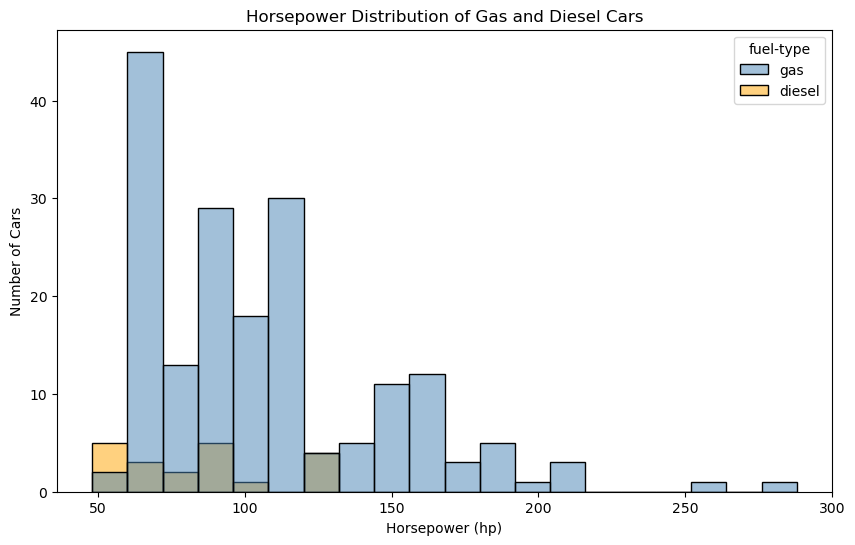

In [14]:

plt.figure(figsize=(10, 6))

sns.histplot(
    data=horsepower_df,
    x="horsepower",
    hue="fuel-type",
    hue_order=["gas", "diesel"],
    bins=20,
    multiple="layer",
    common_bins=True,
    palette={"gas": "steelblue", "diesel": "orange"},
    alpha=0.5
)

plt.title("Horsepower Distribution of Gas and Diesel Cars")
plt.xlabel("Horsepower (hp)")
plt.ylabel("Number of Cars")
plt.show()



**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer: Looking at the histogram I noticed that gas cars have higher horsepower than diesel cars. Most diesel cars are around 50 to 100 hp while gas cars are mostly around 60 to 120 hp. The gas cars also have a bigger spread with some going as high as 288 hp while diesel only goes up to 123 hp.


In [15]:

horsepower_df.groupby("fuel-type")["horsepower"].describe()



,count,mean,std,min,25%,50%,75%,max
fuel-type,,,,,,,,
diesel,20.0,84.450000,25.958418,52.0,62.0,84.0,97.75,123.0
gas,183.0,106.420765,40.402821,48.0,70.0,97.0,118.00,288.0


In [16]:

horsepower_iqr = horsepower_df.groupby("fuel-type")["horsepower"].agg(
    lambda x: x.quantile(0.75) - x.quantile(0.25)
)

horsepower_iqr



fuel-type
diesel    35.75
gas       48.00
Name: horsepower, dtype: float64

**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer: My prediction was correct. The gas cars had a higher horsepower than the diesel cars.Both groups had some overlapping horsepower values. The histogram showed how the horsepower was distributed while the box plot would make it easier to compare the median, spread and outliers.  


### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [17]:

# Check the number of cars in each group
print(horsepower_df["fuel-type"].value_counts())

# Check the highest horsepower cars
automobile_df.loc[
    automobile_df["horsepower"] >= 250,
    ["make", "fuel-type", "horsepower"]
]



fuel-type
gas       183
diesel     20
Name: count, dtype: int64


,make,fuel-type,horsepower
49,jaguar,gas,262.0
129,porsche,gas,288.0


**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer: What made me suspicious is some gas cars had much more horsepower than the others. I checked the original records to see if those numbers were actually in the dataset. The check showed that the higher values were recorded and that there were 183 gas cars and 20 diesel cars in the comparison. 


### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer: Based on the results gas cars had higher horsepower than diesel cars in this dataset. The gas cars had an average of 106.42 hp compared to 84.45 hp for diesel. The median was also higher at 97 hp compared to 84 hp. Gas cars had more spread with an IQR of 48 hp compared to 35.75 hp for diesel.


### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer: I wouldn't say that all gas cars have more horsepower than diesel cars just because of this dataset. The data is from older cars and there are a lot more gas cars than diesel cars. Other things like engine size and the type of car could also affect horsepower. The results show a difference in this dataset but don't prove that using gas causes a car to have more horsepower.


## Investigation 2

### Step 1: Question


**What is research question 2? Name the quantitative feature, its units, and the categorical groups.**

Your answer: I want to see if there is a difference in vehicle prices depending on whether a car has front-wheel drive, rear-wheel drive, or four-wheel drive. The quantitative feature is price measured in US dollars and the categorical groups are fwd, rwd, and 4wd.


**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer: My prediction is that rear-wheel-drive cars will have higher prices on average because some sports and luxury cars use rear-wheel drive. I also think rear-wheel-drive cars will have a bigger spread in prices.


### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer: I will use the automobile records that have a drive-wheel type and price listed. Each row represents one car and I will compare the prices in US dollars for fwd, rwd, and 4wd cars. If a car is missing its price I won't include it in this comparison but I will keep the original dataset unchanged.


In [18]:

price_df = automobile_df[
    ["drive-wheels", "price"]
].dropna().copy()

price_df.head()



,drive-wheels,price
0,rwd,13495.0
1,rwd,16500.0
2,rwd,16500.0
3,fwd,13950.0
4,4wd,17450.0


In [19]:

price_df["drive-wheels"].value_counts()



drive-wheels
fwd    118
rwd     75
4wd      8
Name: count, dtype: int64

### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


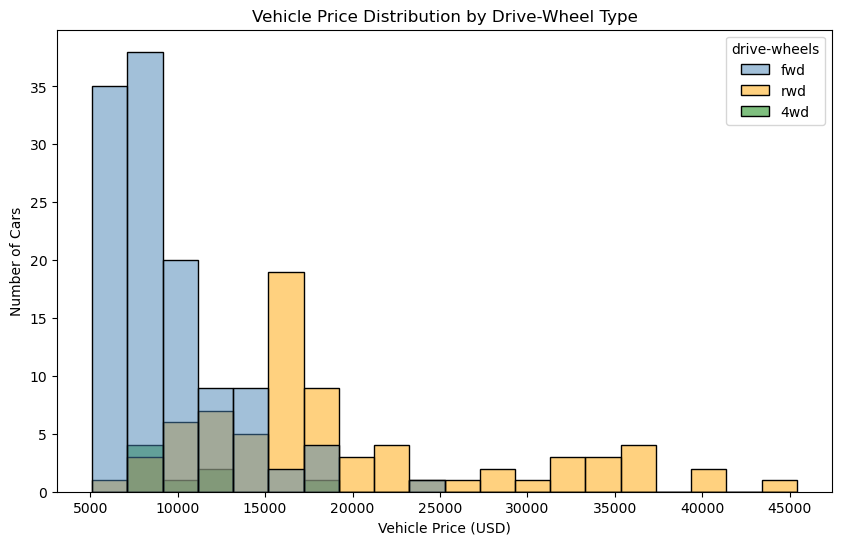

In [20]:

plt.figure(figsize=(10, 6))

sns.histplot(
    data=price_df,
    x="price",
    hue="drive-wheels",
    hue_order=["fwd", "rwd", "4wd"],
    bins=20,
    multiple="layer",
    common_bins=True,
    palette={
        "fwd": "steelblue",
        "rwd": "orange",
        "4wd": "green"
    },
    alpha=0.5
)

plt.title("Vehicle Price Distribution by Drive-Wheel Type")
plt.xlabel("Vehicle Price (USD)")
plt.ylabel("Number of Cars")
plt.show()



**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer: The histogram showa that most of the front wheel drive cars are about 5000-15000 dollars. While the rear wheel drive cares cost over $40,000. The four wheel drive cars came in between 7000-18000 dollars. here is some overlap between all three groups but rear-wheel-drive cars have more of the expensive vehicles. The prices are right skewed especially for rear-wheel drive because of the higher values. The groups also have different numbers of cars which makes some bars taller than others.


In [21]:

price_summary = price_df.groupby("drive-wheels")["price"].describe()

price_iqr = price_df.groupby("drive-wheels")["price"].agg(
    lambda x: x.quantile(0.75) - x.quantile(0.25)
)

print(price_summary)
print("\nIQR by drive-wheel type:")
print(price_iqr)



              count          mean          std     min       25%      50%  \
drive-wheels                                                                
4wd             8.0  10241.000000  3288.211064  7603.0   7984.25   9005.5   
fwd           118.0   9244.779661  3345.898257  5118.0   6950.75   8192.0   
rwd            75.0  19757.613333  9082.575728  6785.0  13455.00  16900.0   

                   75%      max  
drive-wheels                     
4wd           11367.75  17450.0  
fwd           10332.50  23875.0  
rwd           22547.50  45400.0  

IQR by drive-wheel type:
drive-wheels
4wd    3383.50
fwd    3381.75
rwd    9092.50
Name: price, dtype: float64


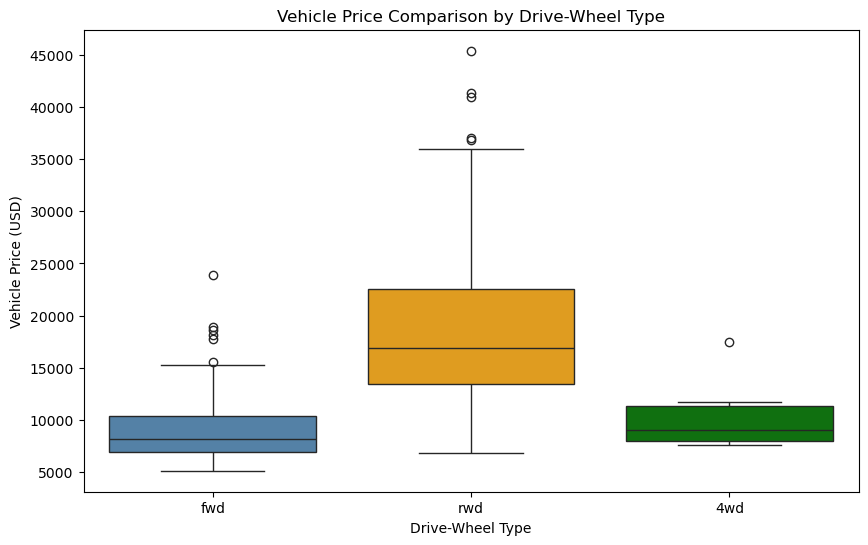

In [22]:

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=price_df,
    x="drive-wheels",
    y="price",
    order=["fwd", "rwd", "4wd"],
    hue="drive-wheels",
    hue_order=["fwd", "rwd", "4wd"],
    palette={
        "fwd": "steelblue",
        "rwd": "orange",
        "4wd": "green"
    },
    legend=False
)

plt.title("Vehicle Price Comparison by Drive-Wheel Type")
plt.xlabel("Drive-Wheel Type")
plt.ylabel("Vehicle Price (USD)")
plt.show()



**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer: I noticed that rear-wheel-drive cars had a higher median price around $17,000 while front-wheel-drive cars were around $8,000 and four-wheel-drive cars around $9,000. Rear-wheel-drive cars also had a bigger spread in prices with some cars costing over $45,000. Front-wheel-drive and four-wheel-drive cars had more similar prices with some overlap between all three groups. The histogram showed how many cars were in each price range while the box plot made it easier to compare the median, spread, and outliers. This supports my prediction that rear-wheel-drive cars would have higher prices.

### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [23]:

# Check group sizes
print(price_df["drive-wheels"].value_counts())

# Check expensive cars in the original dataset
automobile_df.loc[
    automobile_df["price"] >= 40000,
    ["make", "drive-wheels", "price"]
]




drive-wheels
fwd    118
rwd     75
4wd      8
Name: count, dtype: int64


,make,drive-wheels,price
16,bmw,rwd,41315.0
73,mercedes-benz,rwd,40960.0
74,mercedes-benz,rwd,45400.0


**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer: he higher prices for some rear-wheel-drive cars made me suspicious because a few cost over $40,000. I checked the original records to see if those prices were actually in the dataset. If they match the original records I would keep them because being expensive doesn't automatically mean the price is wrong. I would still need more information to know if every price was accurate.

### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer: Based on the graphs rear-wheel-drive cars had higher prices than front-wheel-drive and four-wheel-drive cars. The median for rear-wheel drive was around $17,000 while front-wheel drive was around $8,000 and four-wheel drive was around $9,000. Rear-wheel-drive cars also had a much bigger spread with prices going over $45,000. There was some overlap between the groups but rear-wheel-drive cars had more of the expensive vehicles. This supports my prediction that rear-wheel-drive cars would cost more.


### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer: I wouldn't say that rear-wheel drive automatically makes a car more expensive. The dataset includes different types of cars and other things like the brand, engine size, and features could affect the price. The cars are also from older data so the prices wouldn't represent what cars cost today. This only shows the differences in this dataset.


## Investigation 3

### Step 1: Question


**What is research question 3? Name the quantitative feature, its units, and the categorical groups.**

Your answer: I want to see if different car body styles have different highway gas mileage. The quantitative feature is highway MPG and the categorical groups are sedan, hatchback, wagon, hardtop, and convertible.


**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer: I predict that hatchbacks will have higher highway MPG because they are usually smaller cars. I think wagons will have lower MPG because they are bigger and heavier. I also expect some overlap between the different body styles because not every car is built the same.


### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer: I will use the automobile records that have a body style and highway MPG listed. Each row represents one car and I will compare gas mileage between the different body styles. MPG means miles per gallon. I won't remove any valid values and I'll keep the original dataset unchanged.


In [24]:

mpg_df = automobile_df[
    ["body-style", "highway-mpg"]
].dropna().copy()

mpg_df.head()



,body-style,highway-mpg
0,convertible,27
1,convertible,27
2,hatchback,26
3,sedan,30
4,sedan,22


In [25]:

mpg_df["body-style"].value_counts()



body-style
sedan          96
hatchback      70
wagon          25
hardtop         8
convertible     6
Name: count, dtype: int64

### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


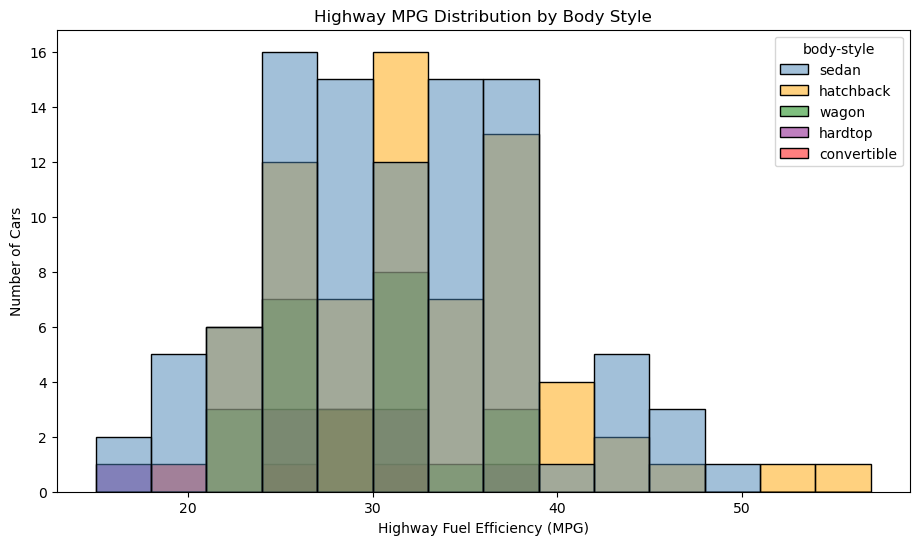

In [26]:

plt.figure(figsize=(11, 6))

sns.histplot(
    data=mpg_df,
    x="highway-mpg",
    hue="body-style",
    hue_order=["sedan", "hatchback", "wagon", "hardtop", "convertible"],
    bins=range(15, 60, 3),
    multiple="layer",
    common_bins=True,
    palette={
        "sedan": "steelblue",
        "hatchback": "orange",
        "wagon": "green",
        "hardtop": "purple",
        "convertible": "red"
    },
    alpha=0.5
)

plt.title("Highway MPG Distribution by Body Style")
plt.xlabel("Highway Fuel Efficiency (MPG)")
plt.ylabel("Number of Cars")
plt.show()



**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer: The histogram I showed that most cars were around 25 to 40 MPG. Hatchbacks seem to have some of the higher MPG values with a few going over 50 MPG. Sedans also have a pretty big spread going from around 15 to 50 MPG. Wagons were mostly around 20 to 40 MPG while hardtops and convertibles had fewer cars. There was a lot of overlap between the different body styles. The sedan and hatchback bars were taller because there are more of those cars in the dataset. Since hardtops and convertibles have fewer cars it is harder to compare their distributions.


In [27]:

mpg_summary = mpg_df.groupby("body-style")["highway-mpg"].describe()

mpg_iqr = mpg_df.groupby("body-style")["highway-mpg"].agg(
    lambda x: x.quantile(0.75) - x.quantile(0.25)
)

print(mpg_summary)
print("\nIQR by body style:")
print(mpg_iqr)



             count       mean       std   min    25%   50%    75%   max
body-style                                                             
convertible    6.0  26.000000  4.289522  18.0  25.50  27.0  28.50  30.0
hardtop        8.0  27.250000  6.088631  16.0  25.00  27.5  30.00  37.0
hatchback     70.0  32.171429  7.044314  22.0  26.25  31.5  38.00  54.0
sedan         96.0  30.833333  7.174027  16.0  25.00  30.5  36.25  50.0
wagon         25.0  28.720000  4.703899  22.0  25.00  29.0  32.00  37.0

IQR by body style:
body-style
convertible     3.00
hardtop         5.00
hatchback      11.75
sedan          11.25
wagon           7.00
Name: highway-mpg, dtype: float64


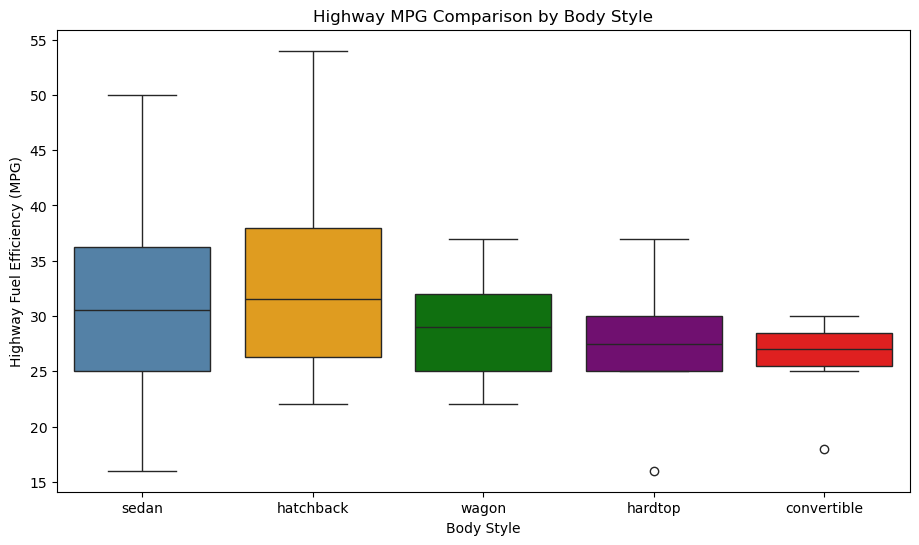

In [28]:

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=mpg_df,
    x="body-style",
    y="highway-mpg",
    order=["sedan", "hatchback", "wagon", "hardtop", "convertible"],
    hue="body-style",
    hue_order=["sedan", "hatchback", "wagon", "hardtop", "convertible"],
    palette={
        "sedan": "steelblue",
        "hatchback": "orange",
        "wagon": "green",
        "hardtop": "purple",
        "convertible": "red"
    },
    legend=False
)

plt.title("Highway MPG Comparison by Body Style")
plt.xlabel("Body Style")
plt.ylabel("Highway Fuel Efficiency (MPG)")
plt.show()



**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer: Looking at the box plot my prediction seems to be right about hatchbacks having higher MPG. Hatchbacks had a median around 32 MPG while sedans were around 30 MPG. Wagons were around 29 MPG while hardtops and convertibles were around 27 MPG. Hatchbacks and sedans also had a bigger spread than the other groups. There was a lot of overlap between the body styles but hatchbacks had some of the highest MPG values going up to 54. The histogram showed how many cars were in each MPG range while the box plot made it easier to see the median, spread and outliers.


### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [29]:

# Check the number of cars in each group
print(mpg_df["body-style"].value_counts())

# Check unusually high and low highway MPG values
automobile_df.loc[
    (automobile_df["highway-mpg"] >= 50) |
    (automobile_df["highway-mpg"] <= 18),
    ["make", "body-style", "highway-mpg"]
]



body-style
sedan          96
hatchback      70
wagon          25
hardtop         8
convertible     6
Name: count, dtype: int64


,make,body-style,highway-mpg
18,chevrolet,hatchback,53
30,honda,hatchback,54
49,jaguar,sedan,17
71,mercedes-benz,sedan,18
72,mercedes-benz,convertible,18
73,mercedes-benz,sedan,16
74,mercedes-benz,hardtop,16
90,nissan,sedan,50


**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer: The higher and lower MPG values made me suspicious because some cars were much different from the others. I checked the original records to see if those numbers were actually in the dataset. The graph showed some cars getting as high as 54 MPG and others as low as 16 MPG. I would keep those values if they match the original records because being different doesn't automatically mean they are wrong. I still can't confirm if every MPG value was measured correctly.


### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer: Based on the results hatchbacks had some of the highest highway MPG values compared to the other body styles. The median was around 32 MPG for hatchbacks and 30 MPG for sedans. Wagons were around 29 MPG while hardtops and convertibles were around 27 MPG. There was a lot of overlap between the groups but hatchbacks had a bigger spread with some reaching 54 MPG. This supports my prediction about hatchbacks but not completely about wagons because some wagons had similar MPG to sedans.


### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer: I wouldn't say that hatchbacks always get better gas mileage than other body styles. The dataset contains older cars and things like engine size, weight, and fuel type can affect MPG. Some body styles also have fewer cars than others which makes them harder to compare. The results show differences in this dataset but don't prove that body style alone causes better gas mileage.


## AI-use reflection


**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Your answer: I used ChatGPT to help me understand the assignment, write some of the Python code, and explain the results. One suggestion I checked was using Pandas to calculate the mean, median, and IQR for the different groups. I compared those results with the graphs to see if they matched. I accepted the suggestion because it helped me compare the data using actual numbers instead of only looking at the graphs. I also checked the original records for unusual values.


## Submission checklist

- Include the new dataset CSV, source citation, dictionary reference, and explanation of why it has not been used in class or a previous lab.
- Document every feature, including meaning, units/codes, conceptual type, storage type, and missing count.
- Identify at least one categorical feature and three distinct quantitative features.
- Complete three different questions, one quantitative feature per question, each with a prediction and all six workflow steps.
- Include a histogram and box plot for each question, grouped summaries and IQRs, and usable group sizes.
- Explain preparation and exclusions; preserve valid extreme values and distinguish missing values from zero.
- Support conclusions about similarities or differences with numerical and visual evidence, contextual checks, and specific limitations.
- Complete every written response and the AI-use reflection.
- Restart the kernel and run every cell in order; use relative paths and ensure all claims match the output.
